# ATMS Module 4 Assignment
### Erin Welch

In [1]:
# imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from eofs.xarray import Eof

import statsmodels as sm
from sklearn.decomposition import PCA

from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler

import cdsapi

In [2]:
# load provided functions

def _time_as_float(time: xr.DataArray, time_dim: str) -> xr.DataArray:
    # numeric seconds since first timestamp (keeps numbers small)
    return (time - time.isel({time_dim: 0})).astype("timedelta64[s]").astype("int64").astype("float64")

def linear_detrend(obj: xr.DataArray | xr.Dataset, time_dim: str = "time") -> xr.DataArray | xr.Dataset:
    """
    Remove a linear trend y ~ s*(t - t̄_valid) + ȳ_valid at each grid point.
    Closed-form LS using reductions; dask-friendly; handles NaNs.
    """
    t = _time_as_float(obj[time_dim], time_dim)  # (time,)
    def _detrend_da(da: xr.DataArray) -> xr.DataArray:
        da = da.sortby(time_dim).astype("float32")
        if hasattr(da.data, "chunks"):
            da = da.chunk({time_dim: -1})  # one chunk along time
        mask = da.notnull()                                # (time, ...)
        t_b = t.broadcast_like(da)                         # (time, ...)
        t_mean_valid = t_b.where(mask).mean(time_dim, skipna=True)
        tc = t_b - t_mean_valid                            # centered time per point
        num = (da * tc).sum(time_dim, skipna=True)
        den = (tc**2).sum(time_dim, skipna=True)
        slope = xr.where(den > 0, num / den, 0.0)
        ybar  = da.mean(time_dim, skipna=True)
        trend = slope * (t_b - t_mean_valid) + ybar
        return (da - trend).astype("float32")
    return obj.map(_detrend_da) if isinstance(obj, xr.Dataset) else _detrend_da(obj)

def monthly_anom_and_z(
    detr: xr.DataArray | xr.Dataset,
    time_dim: str = "time",
    base_period: tuple[str, str] | None = None,
    ddof: int = 1,
    eps: float = 1e-6,
):
    """
    From linearly-detrended data, remove monthly climatology and compute monthly z-scores.
    Returns (anom, z). Works for Dataset or DataArray.
    """
    clim_src = detr if base_period is None else detr.sel({time_dim: slice(*base_period)})
    key = f"{time_dim}.month"

    clim_mean = clim_src.groupby(key).mean(time_dim, skipna=True)
    anom = detr.groupby(key) - clim_mean

    clim_std = clim_src.groupby(key).std(time_dim, skipna=True, ddof=ddof)
    safe_std = xr.where(clim_std > eps, clim_std, np.nan)
    z = anom.groupby(key) / safe_std
    return anom, z

1) Create a dataset that contains the monthly means of Sea Surface Temperature anomalies and total column water vapor from Jan 1979-Dec 2024 over the Pacific Basin (65°N to 65°S, 120°E to 60°W) masked out over land - save this to your computer. The data and land sea mask is available here: [https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-monthly-means?tab=download](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-monthly-means?tab=download)

In [3]:
# follow cds api protocol to subset data
client = cdsapi.Client()

# dataset to use
dataset = "reanalysis-era5-single-levels-monthly-means"

# API request
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "year": [
        "1979", "1980", "1981",
        "1982", "1983", "1984",
        "1985", "1986", "1987",
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024"
    ],
    "month": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12"
    ],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived",
    "variable": [
        "sea_surface_temperature",
        "total_column_water_vapour",
        "land_sea_mask"
    ],
    "area": [65, 120, -65, -60]
}

# retrieve
client.retrieve(dataset, request).download()


2025-11-05 11:18:38,761 INFO Request ID is be3f72b6-e78b-44a3-b030-e45201d79187
2025-11-05 11:18:39,036 INFO status has been updated to accepted
2025-11-05 11:18:53,964 INFO status has been updated to running
2025-11-05 11:23:04,006 INFO status has been updated to successful
Recovering from connection error [HTTPSConnectionPool(host='object-store.os-api.cci2.ecmwf.int', port=443): Read timed out.], attempt 1 of 500
Retrying in 120 seconds
Recovering from connection error [HTTPSConnectionPool(host='object-store.os-api.cci2.ecmwf.int', port=443): Read timed out.], attempt 2 of 500
Retrying in 120 seconds


'a3c14ca713be057cdf3c14af79c172e3.nc'

In [3]:
# read in using xarray

ds = xr.open_dataset('a3c14ca713be057cdf3c14af79c172e3.nc')

In [4]:
print(ds)

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver      (valid_time) <U4 9kB ...
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB ...
    tcwv        (valid_time, latitude, longitude) float32 829MB ...
    lsm         (valid_time, latitude, longitude) float32 829MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-11-05T21:21 GRIB to CDM+CF via cfgrib-0.9.1...


In [5]:
# create mask
mask = ds.where(ds['lsm'] == 0)

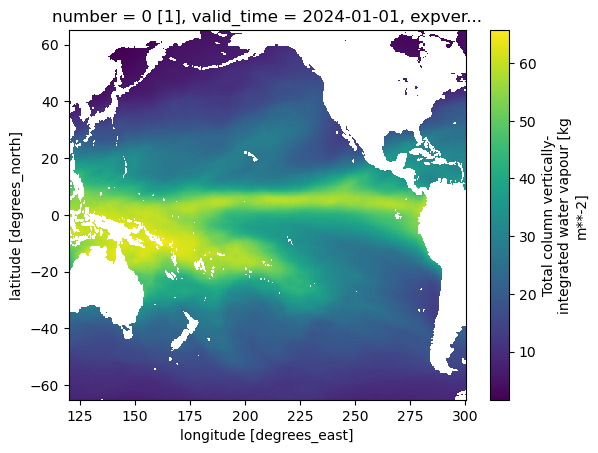

In [6]:
# plot to confirm mask worked and check out our data
mask['tcwv'].sel(valid_time='2024-01-01').plot()

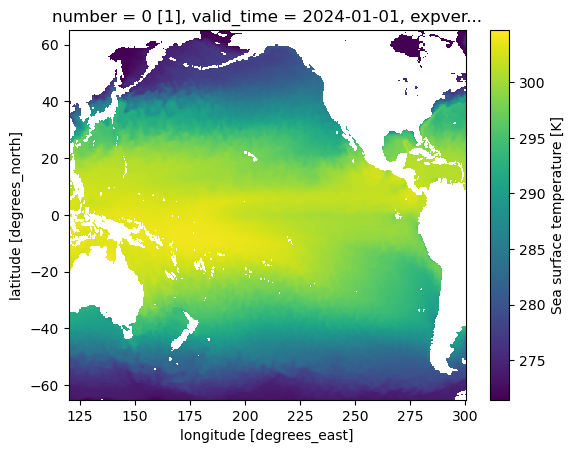

In [7]:
# plot to confirm mask worked and check out our data
mask['sst'].sel(valid_time='2024-01-01').plot()

In [8]:
print(mask)

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB nan nan ... nan
    tcwv        (valid_time, latitude, longitude) float32 829MB nan nan ... nan
    lsm         (valid_time, latitude, longitude) float32 829MB nan nan ... nan
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 20

In [9]:
# save the masked data to netcdf
mask.to_netcdf("pacific_sst_tcwv_mask.nc")

2)  From the dataset shown in 1, compute anomalies by deseasonalizing the data (remove the mean monthly anomaly from the annual mean from each point) and detrend the data. 

In [10]:
# ensure time is a single chunk for speed
mask = mask.chunk({"valid_time": -1})

In [11]:
# detrend/deseasonalize data using provided functions
detr = linear_detrend(mask[["sst", "tcwv"]], time_dim="valid_time")

/opt/anaconda3/envs/climate/lib/python3.11/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


In [12]:
# detrend/deseasonalize data using provided functions
anom, z = monthly_anom_and_z(detr, time_dim="valid_time",
                             base_period=("1981-01-01", "2010-12-31")) 

In [14]:
print(detr)

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(552, 521, 721), meta=np.ndarray>
    tcwv        (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(552, 521, 721), meta=np.ndarray>


In [15]:
print(anom)

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      (valid_time) int64 4kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
    month       (valid_time) int64 4kB 1 2 3 4 5 6 7 8 9 ... 5 6 7 8 9 10 11 12
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(1, 521, 721), meta=np.ndarray>
    tcwv        (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(1, 521, 721), meta=np.ndarray>


In [16]:
print(z)

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      (valid_time) int64 4kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
    month       (valid_time) int64 4kB 1 2 3 4 5 6 7 8 9 ... 5 6 7 8 9 10 11 12
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(1, 521, 721), meta=np.ndarray>
    tcwv        (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(1, 521, 721), meta=np.ndarray>


In [17]:
print(type(z), list(z.data_vars))

<class 'xarray.core.dataset.Dataset'> ['sst', 'tcwv']


3) Perform an EOF analysis on the SST anomalies and plot a map of the first 5 EOFs, following M04N05.

In [18]:
# convert the dataset of detrended data to an array
detr_sst = detr['sst']
print(detr_sst)

<xarray.DataArray 'sst' (valid_time: 552, latitude: 521, longitude: 721)> Size: 829MB
dask.array<astype, shape=(552, 521, 721), dtype=float32, chunksize=(552, 521, 721), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'


In [19]:
# rename time dimension for convenience
detr_sst = detr_sst.rename({'valid_time': 'time'})

In [20]:
print(detr_sst)

<xarray.DataArray 'sst' (time: 552, latitude: 521, longitude: 721)> Size: 829MB
dask.array<astype, shape=(552, 521, 721), dtype=float32, chunksize=(552, 521, 721), chunktype=numpy.ndarray>
Coordinates:
    number     int64 8B 0
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude  (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver     (time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001' '0001'


In [ ]:
# M4N5:
"""
# Create an EOF solver to do the EOF analysis. Square-root of cosine of
# latitude weights are applied before the computation of EOFs.

coslat = np.cos(np.deg2rad(sst.coords['latitude'].values))
wgts = np.sqrt(coslat)[..., np.newaxis]
solver = Eof(sst, weights=wgts)

"""

In [21]:
# conduct EOF computaion using provided code
coslat = np.cos(np.deg2rad(detr_sst.coords['latitude'].values))
wgts = np.sqrt(coslat)[..., np.newaxis]
solver = Eof(detr_sst, weights=wgts)

/opt/anaconda3/envs/climate/lib/python3.11/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/opt/anaconda3/envs/climate/lib/python3.11/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


/opt/anaconda3/envs/climate/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


In [22]:
# conduct EOF computaion using provided code
# retrieve first 5 EOFs and plot

eof1 = solver.eofsAsCorrelation(neofs=5)
pc1 = solver.pcs(npcs=5, pcscaling=1)

/opt/anaconda3/envs/climate/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/climate/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/climate/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/climate/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/climate/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value enco

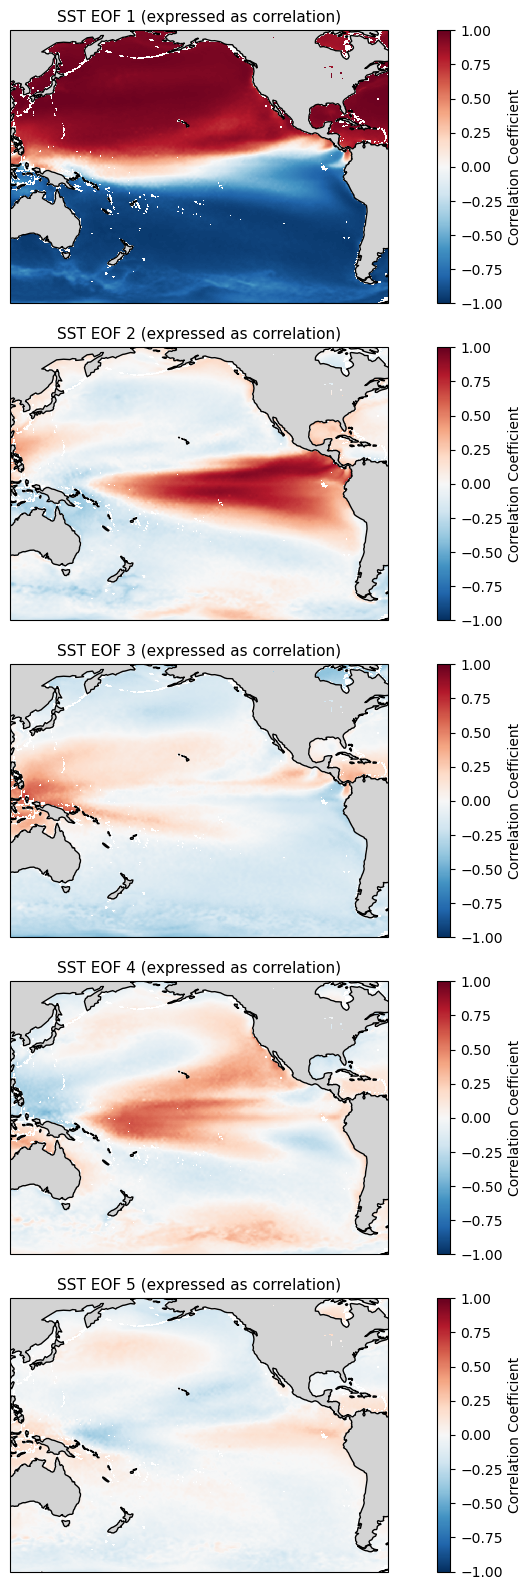

In [23]:
# plot correlation map and timeseries plot for the first 5 EOFs

proj = ccrs.PlateCarree(central_longitude=180)  
fig, axs = plt.subplots(5, 1, figsize=(10, 16), subplot_kw={'projection': proj})

for i in range(5):
    ax = axs[i]
    ax.coastlines(resolution='110m')
    ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='none')

    # set map extent for Pacific Basin (120E–60W = 120 to 300°E)
    ax.set_extent([120, 300, -65, 65], crs=ccrs.PlateCarree())

    # plot EOF correlation pattern
    eof1.isel(mode=i).plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='RdBu_r',
        vmin=-1, vmax=1,
        cbar_kwargs={'label': 'Correlation Coefficient'}
    )
    ax.set_title(f"SST EOF {i+1} (expressed as correlation)", fontsize=11)

plt.tight_layout()
plt.show()

4) Plot the percent of variance explained by the first 10 EOFs.

In [24]:
# compute variance fraction explained by each EOF
varfrac = solver.varianceFraction()

(4.173775940701185e-18, 0.8582785725593567)

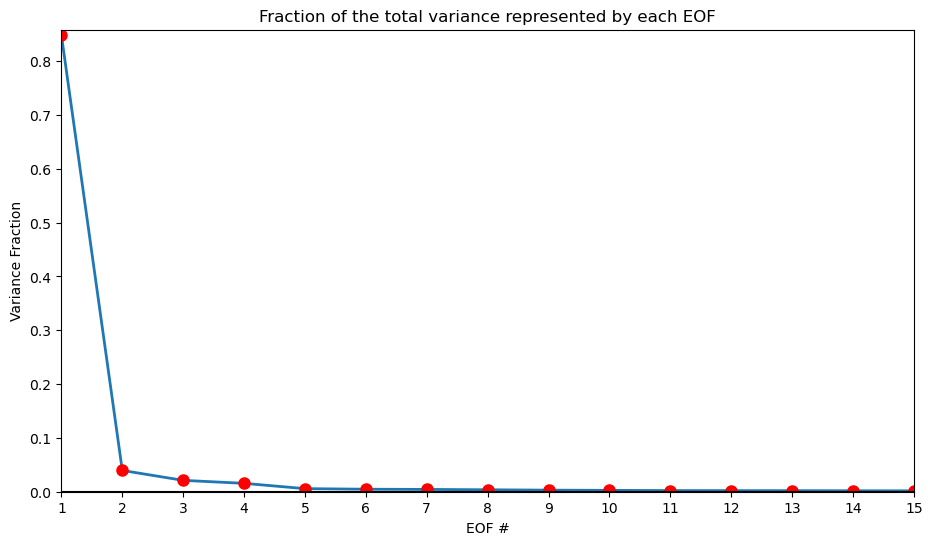

In [25]:
# plot the fraction of variance explained by each EOF
plt.figure(figsize=(11,6))
eof_num = range(1, 16)
plt.plot(eof_num, varfrac[0:15], linewidth=2)
plt.plot(eof_num, varfrac[0:15], linestyle='None', marker="o", color='r', markersize=8)
plt.axhline(0, color='k')
plt.xticks(range(1, 16))
plt.title('Fraction of the total variance represented by each EOF')
plt.xlabel('EOF #')
plt.ylabel('Variance Fraction')
plt.xlim(1, 15)
plt.ylim(np.min(varfrac), np.max(varfrac)+0.01)

5) Reconstruct the SST field using the first 5 EOFs and plot a map of the Pearson's correlation coefficient ([xarray.corr](https://docs.xarray.dev/en/stable/generated/xarray.corr.html)) of the reconstructed monthly time series (which will be "retrended" and "unstandardized") and the "observed" SST time series.

In [26]:
reconstruction = solver.reconstructedField(5)
print(reconstruction)

<xarray.DataArray 'sst' (time: 552, latitude: 521, longitude: 721)> Size: 829MB
dask.array<divide, shape=(552, 521, 721), dtype=float32, chunksize=(552, 521, 721), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude  (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver     (time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001' '0001'
Attributes:
    long_name:  sst_reconstructed_with_5_EOFs


In [27]:
# change time naming back to standard
reconstruction = reconstruction.rename({'time': 'valid_time'})

In [28]:
# retrend the data

trend = ds['sst'] - anom['sst']
recon = reconstruction + trend

In [29]:
# calculate correlation
corr = xr.corr(recon, ds['sst'], dim='valid_time')

/opt/anaconda3/envs/climate/lib/python3.11/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/opt/anaconda3/envs/climate/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


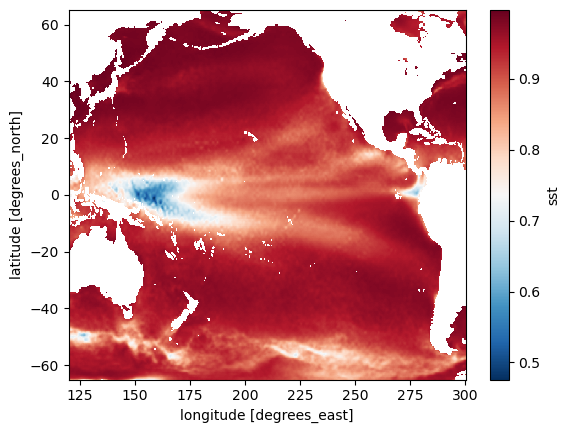

/opt/anaconda3/envs/climate/lib/python3.11/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


In [30]:
# plot
corr.plot(cmap="RdBu_r")

6) Compute a map of the Pearson's correlation coefficient between SST EOF1 and monthly mean detrended, deseasonalized, and standardized monthly mean column water vapor anomalies (don't mask these over land for the plot).  See anything interesting?

In [31]:
# convert the dataset of detrended anomalies to a data array
detr_tcwv = detr['tcwv']
print(detr_tcwv)

<xarray.DataArray 'tcwv' (valid_time: 552, latitude: 521, longitude: 721)> Size: 829MB
dask.array<sub, shape=(552, 521, 721), dtype=float32, chunksize=(1, 521, 721), chunktype=numpy.ndarray>
Coordinates:
    number      (valid_time) int64 4kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
    month       (valid_time) int64 4kB 1 2 3 4 5 6 7 8 9 ... 5 6 7 8 9 10 11 12


In [ ]:
# compute pearson correlation for leading eof
pc1 = solver.pcs(npcs=1, pcscaling=1).squeeze()
corr_eof1 = xr.corr(detr_tcwv, pc1, dim='time')

In [33]:
# plot correlation map for tcwv and eof1
proj = ccrs.PlateCarree(central_longitude=180)

plt.figure(figsize=(10,5))
ax = plt.axes(projection=proj)

# correlation
im = corr_eof1.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r',
    vmin=-1, vmax=1,        
    cbar_kwargs={'label': 'Correlation'}
)

ax.set_extent([120, 300, -65, 65], crs=ccrs.PlateCarree())
plt.title('Pearsons Correlation Coefficient of Reconstructed and Observed TCRW')
plt.show()

: 